In [1]:
import pandas as pd
import json
from matplotlib import pyplot as plt

In [2]:
data = []

for scenario in ["real___2013", "real___2022"]:
    with open(f"../data/access/{scenario}/summary.json", 'r') as file:
        _data = json.load(file)
        data.append({
            'YEAR': scenario.split("__")[1], "SCENARIO": scenario+"__solo",
            "WEIGHTED_ACTIVE_IDX": _data["WEIGHTED_ACTIVE_IDX"],
            "WEIGHTED_ACTIVE_IDX___EETU": _data["WEIGHTED_ACTIVE_IDX___EETU"],
            "WEIGHTED_ACTIVE_IDX___ECONOMICZONES": _data["WEIGHTED_ACTIVE_IDX___ECONOMICZONES"],
        })


for scenario in ["housing", "jobs", "network"]:
    with open(f"../data/access/{scenario}___solo/summary.json", 'r') as file:
        _data = json.load(file)
        data.append({
            'YEAR': scenario.split("___")[-1], "SCENARIO": scenario+"__solo",
            "WEIGHTED_ACTIVE_IDX": _data["WEIGHTED_ACTIVE_IDX"],
            "WEIGHTED_ACTIVE_IDX___EETU": _data["WEIGHTED_ACTIVE_IDX___EETU"],
            "WEIGHTED_ACTIVE_IDX___ECONOMICZONES": _data["WEIGHTED_ACTIVE_IDX___ECONOMICZONES"]
        })


df = pd.DataFrame(data)

In [3]:
df

,YEAR,SCENARIO,WEIGHTED_ACTIVE_IDX,WEIGHTED_ACTIVE_IDX___EETU,WEIGHTED_ACTIVE_IDX___ECONOMICZONES
0,_2013,real___2013__solo,686407.124381,1.066395e+06,873202.215555
1,_2022,real___2022__solo,565552.523112,9.284753e+05,734417.620500
2,housing,housing__solo,677714.925159,1.060614e+06,874410.857213
3,jobs,jobs__solo,640144.632710,9.948435e+05,808492.279717
4,network,network__solo,613233.299049,1.001568e+06,788006.015344


In [4]:
originalCols = df.columns
for col in originalCols:
    if 'WEIGHTED' in col:
        baseline = list(df[col])[0]
        df[col+"____PERC"] = 100*(df[col]-baseline)/baseline
df

,YEAR,SCENARIO,WEIGHTED_ACTIVE_IDX,WEIGHTED_ACTIVE_IDX___EETU,WEIGHTED_ACTIVE_IDX___ECONOMICZONES,WEIGHTED_ACTIVE_IDX____PERC,WEIGHTED_ACTIVE_IDX___EETU____PERC,WEIGHTED_ACTIVE_IDX___ECONOMICZONES____PERC
0,_2013,real___2013__solo,686407.124381,1.066395e+06,873202.215555,0.000000,0.000000,0.000000
1,_2022,real___2022__solo,565552.523112,9.284753e+05,734417.620500,-17.606840,-12.933275,-15.893752
2,housing,housing__solo,677714.925159,1.060614e+06,874410.857213,-1.266333,-0.542074,0.138415
3,jobs,jobs__solo,640144.632710,9.948435e+05,808492.279717,-6.739804,-6.709677,-7.410647
4,network,network__solo,613233.299049,1.001568e+06,788006.015344,-10.660412,-6.079106,-9.756755


[0.0, -17.606839581968135, -1.266332896699685, -6.739803540433448, -10.660411690523466]
-17.606839581968135 -18.666548127656597
[0.0, -12.933274996047402, -0.5420742863491818, -6.709677385400441, -6.07910601051382]
-12.933274996047402 -13.330857682263444
[0.0, -15.893752052285206, 0.1384148638657315, -7.410647234514475, -9.756754929532628]
-15.893752052285206 -17.028987300181374


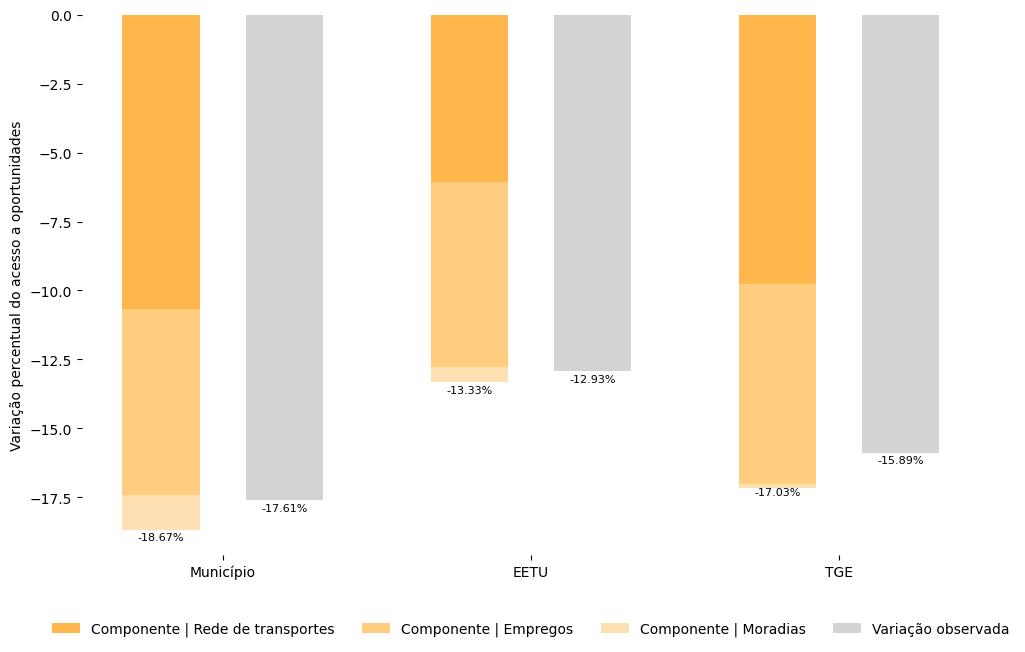

In [6]:
import numpy as np

def get_label_pos(y):
    if y >= 0:
        return y + 1
    else:
        return y-0.45 #1  # posição acima do eixo zero para valores negativos

#x = np.arange(6)  # posições no eixo x
x = [1, 1.8, 3, 3.8, 5, 5.8]

width = 0.5  # largura da barra

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

i = 0

title1 = None
title2 = None
title3 = None
title4 = None

for col in ["WEIGHTED_ACTIVE_IDX____PERC", "WEIGHTED_ACTIVE_IDX___EETU____PERC", "WEIGHTED_ACTIVE_IDX___ECONOMICZONES____PERC"]:
    if i == 4: 
        title1 = "Componente | Rede de transportes"
        title2 = "Componente | Empregos"
        title3 = "Componente | Moradias"
        title4 = "Variação observada"
    values = list(df[col])
    print(values)
    # Barra empilhada no Grupo A
    ax.bar(x[i], values[-1], width, label=title1, color='#ffb74d') # network primeiro (mais representativo)
    ax.bar(x[i], values[-2], width, bottom=values[-1], label=title2, color='#ffcc80')
    ax.bar(x[i], values[-3], width, bottom=values[-2]+values[-1], label=title3, color='#ffe0b2')

    # Barra simples no Grupo B
    ax.bar(x[i+1], values[1], width, label=title4, color='lightgray')

    # Calculando alturas
    altura_stacked = values[-1] + values[-2] + values[-3]

    # Adicionando labels no topo
    ax.text(x[i], get_label_pos(altura_stacked), f'{altura_stacked:.2f}%', 
            ha='center', va='bottom', fontsize=8)

    ax.text(x[i+1], get_label_pos(values[1]), f'{values[1]:.2f}%', 
            ha='center', va='bottom', fontsize=8)

    print(values[1], sum([values[-1], values[-2], values[-3]]))

    i+=2
    #break

# Eixos e rótulos
ax.set_xticks(x)
#ax.set_xticklabels(labels)
ax.set_ylabel('Variação percentual do acesso a oportunidades')
#ax.set_title('Stacked + Barra Simples')
plt.tight_layout()

#xtick_positions = [((x[0]+x[1])/2)*i+i+0.8 for i in range(int(len(x)/2))]
xtick_positions = [1.4, 3.4, 5.4]
xtick_labels = ['Município', 'EETU', 'TGE']

# Aplicar aos ticks do eixo X
ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels)

# Legenda
ax.legend(
    loc='center left',
    bbox_to_anchor=(1.0, 0.5),
    frameon=False
)
ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.1),
    ncol=4,                # legenda em 2 colunas
    frameon=False          # opcional: sem caixa
)
for spine in ax.spines.values():
    spine.set_visible(False)
#plt.savefig("./non_elasticity.png", dpi=1200)
plt.show()